This project explores different pre-processing methods of mammograms before neural network training. The goal of this notebook is to walk you through setting up and using a neural network in Google CoLab. Note that the raw images must be downloaded and set to the correct directory before running this code.

Here is our presentation: https://docs.google.com/presentation/d/164Fi7TkFQRbLIuP3z_y9shHJBSYE3Jp7heBpFcq061U/edit?usp=sharing.

AI DISCLOSURE: All conceptual planning was done entirely by the three members of this team. AI use (Claude and Gemini) was used for troubleshooting the code, especially when loading and integrating some of the more obscure libraries needed for training the neural network.

First, import the libraries needed. Some need to be installed in CoLab.

In [ ]:
#import libraries
import os
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import glob
import shutil
import json
import matplotlib.pyplot as plt
from PIL import Image
from skimage.draw import polygon as sk_polygon
import cv2
import numpy as np

!pip install segmentation-models-pytorch
import segmentation_models_pytorch as smp
model = smp.Unet(
    encoder_name="efficientnet-b0",    # options: b0 through b7
    encoder_weights="imagenet",         # pretrained on ImageNet
    in_channels=3,                      # 1 for grayscale, 3 for RGB
    classes=1,                          # number of output classes
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.0 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Next, mount the Drive. Make sure to set the correct path for your Google Drive set up.

In [ ]:
from google.colab import drive
from google.colab import drive
drive.mount('/content/drive')
# paul's
finalProjectFolderPath = '/content/drive/MyDrive/Duke/BME303/finalProject'
rawDataFolderPath = '/content/drive/MyDrive/Duke/BME303/finalProject/rawData'
resultsFolderPath = '/content/drive/MyDrive/Duke/BME303/finalProject/results'

#ella
#finalProjectFolderPath = '/content/drive/MyDrive/finalProject'
#rawDataFolderPath = '/content/drive/MyDrive/finalProject/rawData'
#resultsFolderPath = '/content/drive/MyDrive/finalProject/results'


Mounted at /content/drive


The first step of this project is checking our dataset. The raw images (PNG) and annotations (JSON) should both be zips. The original dataset came from TOMPEI-CMMD (https://www.cancerimagingarchive.net/analysis-result/tompei-cmmd/) as DICOM and were converted to PNG by this team for ease of use.

In [ ]:
# Copy the archives to the local Colab disk (force overwrite)
!cp -f {rawDataFolderPath}/dataset.zip /content/
!cp -f {rawDataFolderPath}/TOMPEI-CMMD_v01_20250123_new.zip /content/

# Create extraction directories
!mkdir -p /content/temp_dataset/images/
!mkdir -p /content/temp_dataset/annotations/

# Unzip them locally
!unzip -o -q /content/dataset.zip -d /content/temp_dataset/images/
!unzip -o -q /content/TOMPEI-CMMD_v01_20250123_new.zip -d /content/temp_dataset/annotations/

# Organize into images and annotations folders
# Assume the following data structure: # dataset has images folder and annotations folder, each of which have the png or json respectively. Image 1 maps to Annotation 1, etc

os.makedirs('/content/dataset/images', exist_ok=True)
os.makedirs('/content/dataset/annotations', exist_ok=True)

# Move all pngs to images and jsons to annotations
for file in glob.glob('/content/temp_dataset/images/**/*.png', recursive=True):
    shutil.move(file, os.path.join('/content/dataset/images', os.path.basename(file)))

for file in glob.glob('/content/temp_dataset/annotations/**/*.json', recursive=True):
    shutil.move(file, os.path.join('/content/dataset/annotations', os.path.basename(file)))

# Clean up temp folder and zip files
!rm -rf /content/temp_dataset/
!rm /content/dataset.zip
!rm /content/TOMPEI-CMMD_v01_20250123_new.zip

print("Dataset unpacked and organized into 'images' and 'annotations' folders.")

Dataset unpacked and organized into 'images' and 'annotations' folders.


Check the total number of images and annotations to make sure that the zips are correct. There should 1013 of both.

In [ ]:
dataset_path = '/content/dataset/'

# Count annotations
annotation_files = glob.glob(os.path.join(dataset_path, 'annotations', '*.json'))

# Count images
image_files = glob.glob(os.path.join(dataset_path, 'images', '*.png'))

print(f"Total number of annotations: {len(annotation_files)}")
print(f"Total number of images: {len(image_files)}")

Total number of annotations: 1013
Total number of images: 1013


Let's see what the annotations look like. The annotations come in json format, so we will need to create a binary mask in order to see it visually.

In [9]:
def annotation_to_mask(ann, height, width):
    """
    Convert a TOMPEI-CMMD JSON annotation to a binary mask.

    The JSON contains a list of annotation objects, each with a 'cgPoints'
    key holding the polygon vertices.
    Multiple annotations (e.g. mass + calcification) are merged into
    a single binary mask.

    Parameters
    ----------
    ann : list or dict
        Parsed JSON annotation. Either a list of annotation dicts,
        or a single dict with a key (e.g. 'shapes' or 'annotations')
        that contains the list.
    height : int
        Image height in pixels.
    width : int
        Image width in pixels.

    Returns
    -------
    mask : np.ndarray
        Binary mask of shape (height, width) with dtype float32.
    """
    mask = np.zeros((height, width), dtype=np.float32)

    # Handle both formats: list of annotations or dict with a wrapper key
    if isinstance(ann, dict):
        # Try common wrapper keys
        if 'annotations' in ann:
            shapes = ann['annotations']
        elif 'shapes' in ann:
            shapes = ann['shapes']
        else:
            # Single annotation dict — wrap it
            shapes = [ann]
    elif isinstance(ann, list):
        shapes = ann
    else:
        return mask

    for shape in shapes:
        # Extract polygon vertices from cgPoints
        points = shape.get('cgPoints', [])

        parsed_points = []
        for pt in points:
            if isinstance(pt, dict):
                if 'x' in pt and 'y' in pt:
                    parsed_points.append([pt['x'], pt['y']])
                elif 'X' in pt and 'Y' in pt:
                    parsed_points.append([pt['X'], pt['Y']])
                else:
                    vals = list(pt.values())
                    if len(vals) >= 2:
                        parsed_points.append([vals[0], vals[1]])
            elif isinstance(pt, (list, tuple)) and len(pt) >= 2:
                parsed_points.append([pt[0], pt[1]])

        # Handle flat lists: [x1, y1, x2, y2, ...]
        if len(parsed_points) < 3 and len(points) >= 6 and isinstance(points[0], (int, float)):
            parsed_points = [[points[i], points[i+1]] for i in range(0, len(points)-1, 2)]

        if len(parsed_points) < 3:
            continue  # Need at least 3 vertices for a polygon

        pts = np.array(parsed_points, dtype=np.float64)

        # cgPoints are stored as [x, y] → separate into row (y) and col (x)
        col_coords = pts[:, 0]
        row_coords = pts[:, 1]

        # Fill polygon using skimage
        rr, cc = sk_polygon(row_coords, col_coords, shape=(height, width))
        mask[rr, cc] = 1.0

    return mask


=== Image Info ===
Image shape: (2294, 1914)
Dtype: uint8
Min/Max: 0/243


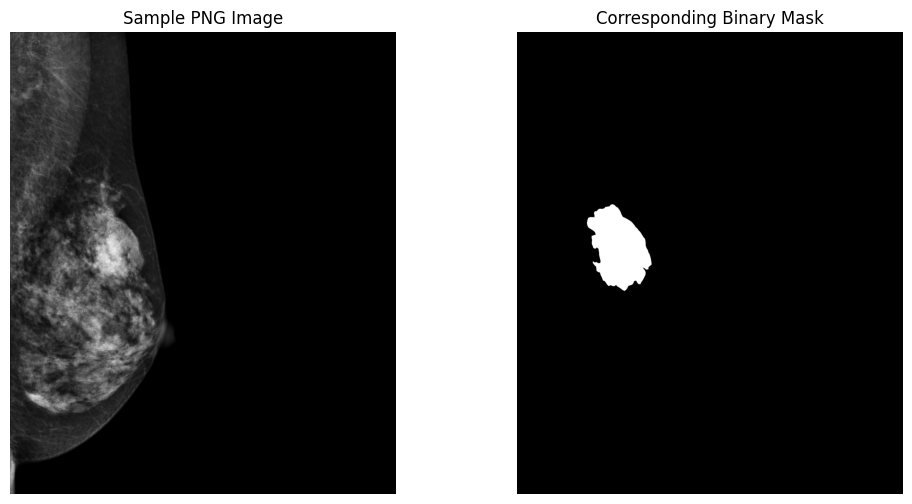

In [ ]:
dataset_path = '/content/dataset/'
annotation_files = sorted(glob.glob(os.path.join(dataset_path, '**', '*.json'), recursive=True))
image_files = sorted(glob.glob(os.path.join(dataset_path, '**', '*.png'), recursive=True))

# Show a PNG image and its corresponding mask
pixel_array = cv2.imread(image_files[0], cv2.IMREAD_GRAYSCALE)
print(f'\n=== Image Info ===')
print(f'Image shape: {pixel_array.shape}')
print(f'Dtype: {pixel_array.dtype}')
print(f'Min/Max: {pixel_array.min()}/{pixel_array.max()}')

with open(annotation_files[0], 'r') as f:
    ann = json.load(f)
mask = annotation_to_mask(ann, pixel_array.shape[0], pixel_array.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(12,6))
ax[0].imshow(pixel_array, cmap='gray')
ax[0].set_title('Sample PNG Image')
ax[0].axis('off')

ax[1].imshow(mask, cmap='gray')
ax[1].set_title('Corresponding Binary Mask')
ax[1].axis('off')
plt.show()

WARNING: do not run the next code (unless you really want to save all the binary mask) as it will be slow. This is OPTIONAL.

In [ ]:
# Save the binary masks

# Ensure results folder exists
binary_masks_folder = os.path.join(resultsFolderPath, 'binaryMasks')
os.makedirs(binary_masks_folder, exist_ok=True)

print(f"\nGenerating and saving all binary masks to {binary_masks_folder}...")

for img_path, ann_path in zip(image_files, annotation_files):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    with open(ann_path, 'r') as f:
        ann_data = json.load(f)

    mask_array = annotation_to_mask(ann_data, img.shape[0], img.shape[1])

    # Generate a filename for the mask based on the image name
    base_name = os.path.basename(img_path).replace('.png', '_mask.png')
    save_path = os.path.join(binary_masks_folder, base_name)

    # Save mask as image (scale 0-1 to 0-255)
    cv2.imwrite(save_path, (mask_array * 255).astype(np.uint8))

print("Mask generation complete.")


Generating and saving all binary masks to /content/drive/MyDrive/Duke/BME303/finalProject/results/binaryMasks...
Mask generation complete.


Now, let's explore two methods of pre-processing. First, we will apply a median filter with CLAHE. Make sure to plot the histogram distribution before and after to see the difference (look at the x and y axis closely).

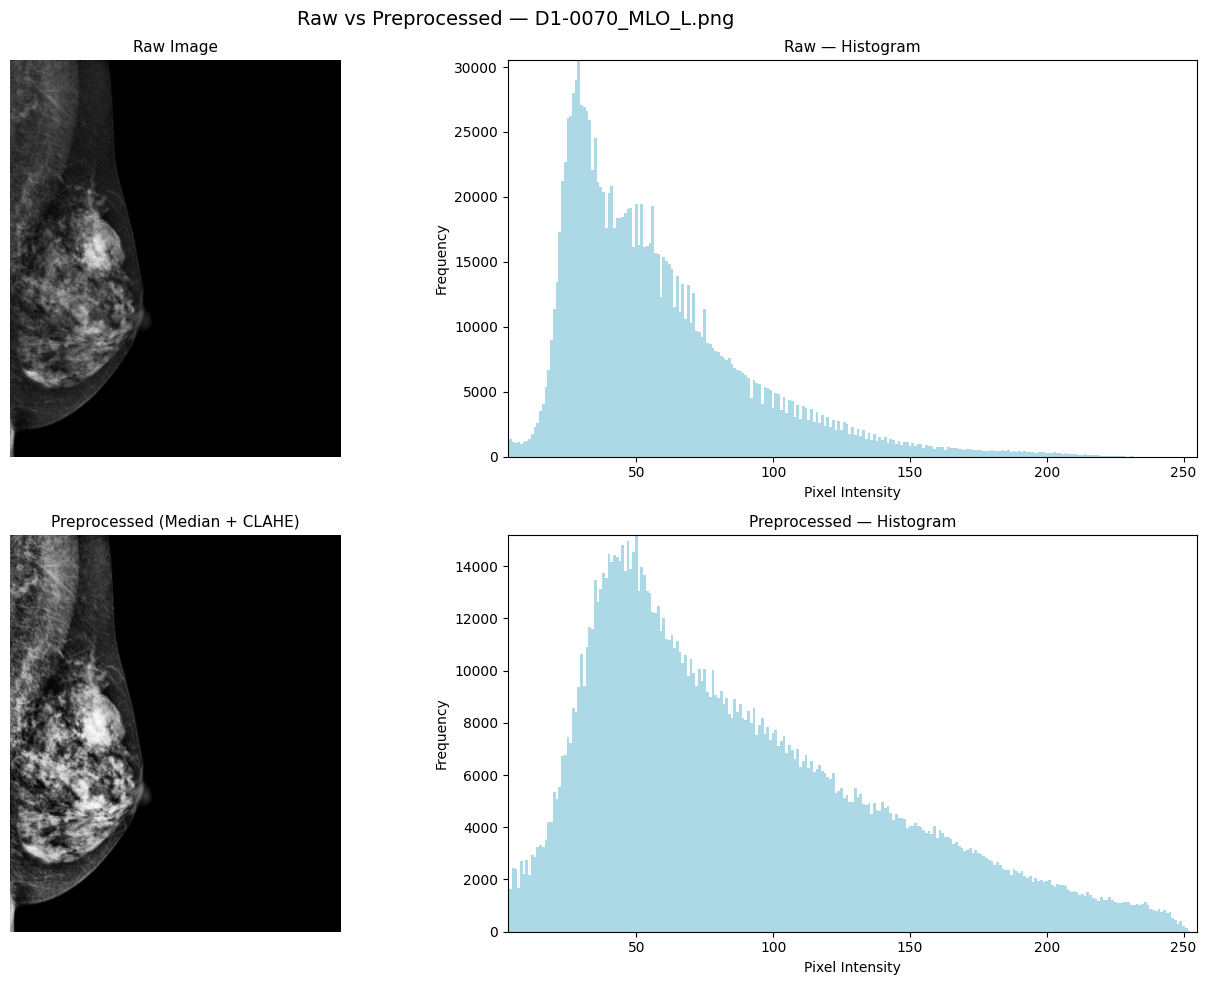

Saving all CLAHE preprocessed images locally... This may take a while.
Processed 100/1013 CLAHE images...
Processed 200/1013 CLAHE images...
Processed 300/1013 CLAHE images...
Processed 400/1013 CLAHE images...
Processed 500/1013 CLAHE images...
Processed 600/1013 CLAHE images...
Processed 700/1013 CLAHE images...
Processed 800/1013 CLAHE images...
Processed 900/1013 CLAHE images...
Processed 1000/1013 CLAHE images...
Finished saving all CLAHE images.


In [ ]:
#Pre-process

# Display sample image vs preprocessed with histograms
from scipy.ndimage import median_filter
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocess_mammogram(image_path):
    # 1. Load PNG in grayscale
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # 2. Normalize to 0-255
    image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # 3. Median filtering
    image = median_filter(image, size=3)
    image = np.array(image, dtype=np.uint8)  # cast back to uint8 after median

    # 4. CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    image = clahe.apply(image)

    return image

def plot_hist(ax, image, title):
    """Plot histogram excluding black background pixels (value=0)"""
    hist = cv2.calcHist([image], [0], None, [255], [1, 256]).flatten()
    ax.bar(range(1, 256), hist, color='lightblue', width=1)
    ax.set_title(title, fontsize=11)
    ax.set_xlim([3, 255])
    ax.set_ylim([0,max(hist[3:])])
    ax.set_xlabel('Pixel Intensity')
    ax.set_ylabel('Frequency')

# ── Use the first image as sample ─────────────────────────
sample_path = image_files[0]
raw = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
processed = preprocess_mammogram(sample_path)

# ── 2x2 grid: image | histogram for each ──────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Raw vs Preprocessed — {os.path.basename(sample_path)}', fontsize=14)

# Row 1: Raw
axes[0][0].imshow(raw, cmap='gray')
axes[0][0].set_title('Raw Image', fontsize=11)
axes[0][0].axis('off')
plot_hist(axes[0][1], raw, 'Raw — Histogram')

# Row 2: Preprocessed
axes[1][0].imshow(processed, cmap='gray')
axes[1][0].set_title('Preprocessed (Median + CLAHE)', fontsize=11)
axes[1][0].axis('off')
plot_hist(axes[1][1], processed, 'Preprocessed — Histogram')

plt.tight_layout()
plt.show()

# ── Save all CLAHE preprocessed images locally ────────────
local_clahe_folder = '/content/dataset/preProcessed_CLAHE'
os.makedirs(local_clahe_folder, exist_ok=True)

print("Saving all CLAHE preprocessed images locally... This may take a while.")
for i, img_path in enumerate(image_files):
    base_name = os.path.basename(img_path).replace('.png', '')
    clahe_processed = preprocess_mammogram(img_path)
    clahe_img_path = os.path.join(local_clahe_folder, f'{base_name}_clahe.png')
    cv2.imwrite(clahe_img_path, clahe_processed)
    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(image_files)} CLAHE images...")
print("Finished saving all CLAHE images.")

Let's try another method of pre-processing, which is PCA. Compare both methods of pre-processing with the original, raw image.

Original shape: (2294, 1914)


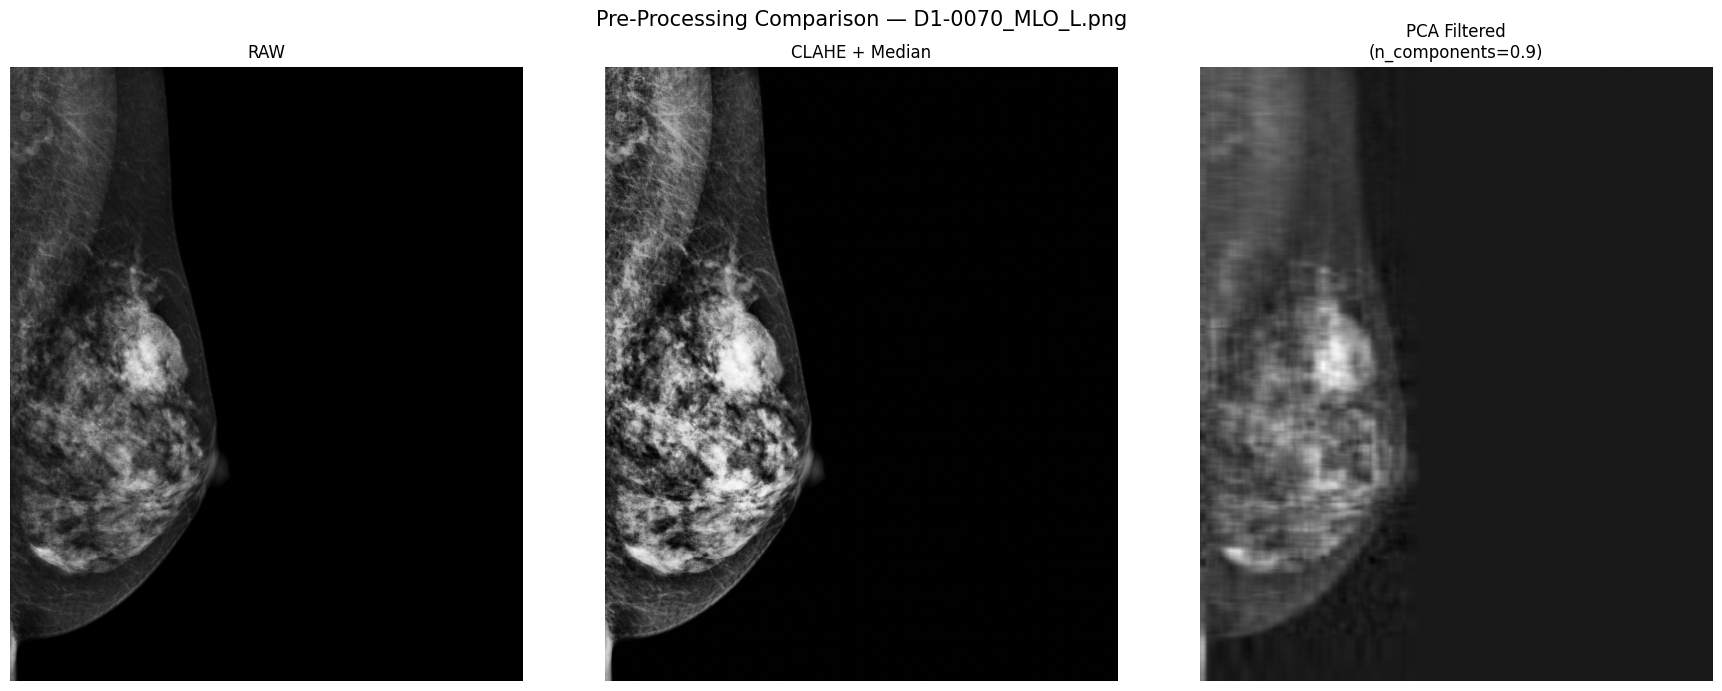

Saving all PCA preprocessed images locally... This may take a while.
Processed 100/1013 PCA images...
Processed 200/1013 PCA images...
Processed 300/1013 PCA images...
Processed 400/1013 PCA images...
Processed 500/1013 PCA images...
Processed 600/1013 PCA images...
Processed 700/1013 PCA images...
Processed 800/1013 PCA images...
Processed 900/1013 PCA images...
Processed 1000/1013 PCA images...
Finished saving all PCA images.


In [ ]:
#PCA Pre Process

from sklearn.decomposition import PCA
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt

def pca_filter(img, n_components):
    """
    PCA filtering — reconstruct image using only the top n_components.
    Lower n_components = more signal loss, fewer components = blurrier/less info.
    """
    img_float = img.astype(np.float32)

    pca = PCA(n_components=n_components)
    transformed = pca.fit_transform(img_float)
    reconstructed = pca.inverse_transform(transformed)

    # Normalize back to uint8
    reconstructed = reconstructed - reconstructed.min()
    if reconstructed.max() > 0:
        reconstructed = reconstructed / reconstructed.max() * 255
    return reconstructed.astype(np.uint8)

# n_components as a fraction of total columns — easier to reason about
# 0.99 = keeps 99% of variance (barely any loss)
# 0.50 = keeps 50% of variance (moderate loss)
# 0.10 = keeps 10% of variance (severe loss)
n_components = 0.9
pca_filtered = pca_filter(raw, n_components=n_components)

print(f'Original shape: {processed.shape}')

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.suptitle(f'Pre-Processing Comparison — {os.path.basename(sample_path)}', fontsize=15)

axes[0].imshow(raw, cmap='gray')
axes[0].set_title('RAW', fontsize=12)
axes[0].axis('off')

axes[1].imshow(processed, cmap='gray')
axes[1].set_title('CLAHE + Median', fontsize=12)
axes[1].axis('off')

axes[2].imshow(pca_filtered, cmap='gray')
axes[2].set_title(f'PCA Filtered\n(n_components={n_components})', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

# ── Save all PCA preprocessed images locally ──────────────
local_pca_folder = '/content/dataset/preProcessed_PCA'
os.makedirs(local_pca_folder, exist_ok=True)

print("Saving all PCA preprocessed images locally... This may take a while.")
for i, img_path in enumerate(image_files):
    base_name = os.path.basename(img_path).replace('.png', '')
    raw_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if raw_img is None:
        continue
    pca_processed = pca_filter(raw_img, n_components=0.9)
    pca_img_path = os.path.join(local_pca_folder, f'{base_name}_pca.png')
    cv2.imwrite(pca_img_path, pca_processed)
    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(image_files)} PCA images...")
print("Finished saving all PCA images.")

WARNING: only run the next 4 cells to save the pre-processing files. This is SLOW and OPTIONAL.

In [ ]:
import shutil
import os

# 1. Save Preprocessed Images to Google Drive

local_clahe_folder = '/content/dataset/preProcessed_CLAHE'
local_pca_folder = '/content/dataset/preProcessed_PCA'

drive_clahe_folder = os.path.join(resultsFolderPath, 'preProcessed_CLAHE')
drive_pca_folder = os.path.join(resultsFolderPath, 'preProcessed_PCA')

print(f"Copying CLAHE preprocessed images to {drive_clahe_folder}... This may take a while.")
shutil.copytree(local_clahe_folder, drive_clahe_folder, dirs_exist_ok=True)

print(f"Copying PCA preprocessed images to {drive_pca_folder}... This may take a while.")
shutil.copytree(local_pca_folder, drive_pca_folder, dirs_exist_ok=True)

print("Finished saving preprocessed images to Google Drive.")

Copying CLAHE preprocessed images to /content/drive/MyDrive/Duke/BME303/finalProject/results/preProcessed_CLAHE... This may take a while.
Copying PCA preprocessed images to /content/drive/MyDrive/Duke/BME303/finalProject/results/preProcessed_PCA... This may take a while.
Finished saving preprocessed images to Google Drive.


In [ ]:
# 2. Save Raw Histograms
raw_hist_folder = os.path.join(resultsFolderPath, 'rawHistogram')
os.makedirs(raw_hist_folder, exist_ok=True)

print("Saving raw histograms... This may take a while.")
for i, img_path in enumerate(image_files):
    base_name = os.path.basename(img_path).replace('.png', '')

    raw = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        continue

    # Create and save raw histogram
    fig_raw_hist, ax_raw = plt.subplots(figsize=(6, 4))
    plot_hist(ax_raw, raw, f'Raw — Histogram ({base_name})')
    raw_hist_path = os.path.join(raw_hist_folder, f'{base_name}_raw_hist.png')
    fig_raw_hist.savefig(raw_hist_path, bbox_inches='tight')
    plt.close(fig_raw_hist)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(image_files)} raw histograms...")

print("Finished saving raw histograms.")

Saving raw histograms... This may take a while.
Processed 100/1013 raw histograms...
Processed 200/1013 raw histograms...
Processed 300/1013 raw histograms...
Processed 400/1013 raw histograms...
Processed 500/1013 raw histograms...
Processed 600/1013 raw histograms...
Processed 700/1013 raw histograms...
Processed 800/1013 raw histograms...
Processed 900/1013 raw histograms...
Processed 1000/1013 raw histograms...
Finished saving raw histograms.


In [ ]:
# 3. Save Preprocessed Histograms
clahe_hist_folder = os.path.join(resultsFolderPath, 'preprocessedHistogram_CLAHE')
pca_hist_folder = os.path.join(resultsFolderPath, 'preprocessedHistogram_PCA')
os.makedirs(clahe_hist_folder, exist_ok=True)
os.makedirs(pca_hist_folder, exist_ok=True)

print("Saving preprocessed histograms... This may take a while.")
for i, img_path in enumerate(image_files):
    base_name = os.path.basename(img_path).replace('.png', '')

    raw = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        continue

    # CLAHE Histogram
    clahe_processed = preprocess_mammogram(img_path)
    fig_clahe, ax_clahe = plt.subplots(figsize=(6, 4))
    plot_hist(ax_clahe, clahe_processed, f'CLAHE — Histogram ({base_name})')
    clahe_path = os.path.join(clahe_hist_folder, f'{base_name}_clahe_hist.png')
    fig_clahe.savefig(clahe_path, bbox_inches='tight')
    plt.close(fig_clahe)

    # PCA Histogram
    pca_processed = pca_filter(raw, n_components=0.9)
    fig_pca, ax_pca = plt.subplots(figsize=(6, 4))
    plot_hist(ax_pca, pca_processed, f'PCA — Histogram ({base_name})')
    pca_path = os.path.join(pca_hist_folder, f'{base_name}_pca_hist.png')
    fig_pca.savefig(pca_path, bbox_inches='tight')
    plt.close(fig_pca)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(image_files)} preprocessed histograms...")

print("Finished saving preprocessed histograms.")

Saving preprocessed histograms... This may take a while.
Processed 100/1013 preprocessed histograms...
Processed 200/1013 preprocessed histograms...
Processed 300/1013 preprocessed histograms...
Processed 400/1013 preprocessed histograms...
Processed 500/1013 preprocessed histograms...
Processed 600/1013 preprocessed histograms...
Processed 700/1013 preprocessed histograms...
Processed 800/1013 preprocessed histograms...
Processed 900/1013 preprocessed histograms...
Processed 1000/1013 preprocessed histograms...
Finished saving preprocessed histograms.


In [ ]:
# 4. Save Combined Comparisons
combined_comparison_folder = os.path.join(resultsFolderPath, 'combinedComparison')
os.makedirs(combined_comparison_folder, exist_ok=True)

print("Saving combined comparisons... This may take a while.")
for i, img_path in enumerate(image_files):
    base_name = os.path.basename(img_path).replace('.png', '')

    raw = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        continue

    clahe_processed = preprocess_mammogram(img_path)
    pca_processed = pca_filter(raw, n_components=0.9)

    # Create and save combined comparison
    fig, axes = plt.subplots(3, 2, figsize=(14, 15))
    fig.suptitle(f'Raw vs CLAHE vs PCA — {os.path.basename(img_path)}', fontsize=14)

    # Raw
    axes[0][0].imshow(raw, cmap='gray')
    axes[0][0].set_title('Raw Image', fontsize=11)
    axes[0][0].axis('off')
    plot_hist(axes[0][1], raw, 'Raw — Histogram')

    # CLAHE
    axes[1][0].imshow(clahe_processed, cmap='gray')
    axes[1][0].set_title('CLAHE (Median + CLAHE)', fontsize=11)
    axes[1][0].axis('off')
    plot_hist(axes[1][1], clahe_processed, 'CLAHE — Histogram')

    # PCA
    axes[2][0].imshow(pca_processed, cmap='gray')
    axes[2][0].set_title('PCA (n_components=0.9)', fontsize=11)
    axes[2][0].axis('off')
    plot_hist(axes[2][1], pca_processed, 'PCA — Histogram')

    plt.tight_layout()
    combined_fig_path = os.path.join(combined_comparison_folder, f'{base_name}_combined.png')
    fig.savefig(combined_fig_path, bbox_inches='tight')
    plt.close(fig)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(image_files)} combined comparisons...")

print("Finished saving combined comparisons.")

Saving combined comparisons... This may take a while.
Processed 100/1013 combined comparisons...
Processed 200/1013 combined comparisons...
Processed 300/1013 combined comparisons...
Processed 400/1013 combined comparisons...
Processed 500/1013 combined comparisons...
Processed 600/1013 combined comparisons...
Processed 700/1013 combined comparisons...
Processed 800/1013 combined comparisons...
Processed 900/1013 combined comparisons...
Processed 1000/1013 combined comparisons...
Finished saving combined comparisons.


Now, let's train the model. First, set up a PyTorch Dataset. For this part, it is crucial to use a GPU in CoLab (or locally).

In [ ]:
IMG_SIZE = 256  # Resize all images to 256x256 for simplicity

# ============================================================
# Toggle for Storage Location
# ============================================================
USE_LOCAL_STORAGE = True  # Set to False to load training images directly from Google Drive

class MammogramDataset(Dataset):
    """Dataset that loads PNG images + JSON annotation masks.
    Args:
        pairs: list of (image_path, annotation_path)
        preprocessing_type: None, 'clahe', or 'pca'
        img_size: resize target
        use_local_storage: boolean to toggle local vs drive folder
    """
    def __init__(self, pairs, preprocessing_type=None, img_size=IMG_SIZE, use_local_storage=True):
        self.pairs = pairs
        self.preprocessing_type = preprocessing_type
        self.img_size = img_size
        self.use_local_storage = use_local_storage

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, ann_path = self.pairs[idx]

        # --- Update image path based on storage choice ---
        base_name = os.path.basename(img_path).replace('.png', '')
        if self.preprocessing_type == 'clahe':
            folder = '/content/dataset/preProcessed_CLAHE' if self.use_local_storage else os.path.join(resultsFolderPath, 'preProcessed_CLAHE')
            img_path = os.path.join(folder, f'{base_name}_clahe.png')
        elif self.preprocessing_type == 'pca':
            folder = '/content/dataset/preProcessed_PCA' if self.use_local_storage else os.path.join(resultsFolderPath, 'preProcessed_PCA')
            img_path = os.path.join(folder, f'{base_name}_pca.png')
        else:
            # Raw images
            if not self.use_local_storage:
                # Attempt to route to a Drive folder for raw images if applicable
                # Assumes rawDataFolderPath/images. Falls back to original local path otherwise.
                drive_raw_path = os.path.join(rawDataFolderPath, 'images', os.path.basename(img_path))
                if os.path.exists(os.path.join(rawDataFolderPath, 'images')):
                    img_path = drive_raw_path

        # --- Load PNG image ---
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if image is None:
             raise ValueError(f"Failed to load image at {img_path}")
        image = image.astype(np.float32)

        # --- Load annotation mask ---
        with open(ann_path, 'r') as f:
            ann = json.load(f)
        mask = annotation_to_mask(ann, image.shape[0], image.shape[1])

        # --- Resize ---
        image = cv2.resize(image, (self.img_size, self.img_size))
        mask  = cv2.resize(mask,  (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)

        # --- Normalize to [0, 1] ---
        image = image / (image.max() + 1e-8)

        # --- To tensor: (1, H, W) ---
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask  = torch.tensor(mask,  dtype=torch.float32).unsqueeze(0)

        return image, mask


# ============================================================
# Train / Test Split — 80/20
# ============================================================
pairs = list(zip(image_files, annotation_files))

train_pairs, test_pairs = train_test_split(pairs, test_size=0.2, random_state=42)
print(f'Training samples: {len(train_pairs)}')
print(f'Test samples:     {len(test_pairs)}')

# Create datasets for all three conditions
train_ds_raw = MammogramDataset(train_pairs, preprocessing_type=None, use_local_storage=USE_LOCAL_STORAGE)
test_ds_raw  = MammogramDataset(test_pairs,  preprocessing_type=None, use_local_storage=USE_LOCAL_STORAGE)

train_ds_clahe = MammogramDataset(train_pairs, preprocessing_type='clahe', use_local_storage=USE_LOCAL_STORAGE)
test_ds_clahe  = MammogramDataset(test_pairs,  preprocessing_type='clahe', use_local_storage=USE_LOCAL_STORAGE)

train_ds_pca = MammogramDataset(train_pairs, preprocessing_type='pca', use_local_storage=USE_LOCAL_STORAGE)
test_ds_pca  = MammogramDataset(test_pairs,  preprocessing_type='pca', use_local_storage=USE_LOCAL_STORAGE)

BATCH_SIZE = 4
train_loader_raw = DataLoader(train_ds_raw, batch_size=BATCH_SIZE, shuffle=True)
test_loader_raw  = DataLoader(test_ds_raw,  batch_size=BATCH_SIZE, shuffle=False)

train_loader_clahe = DataLoader(train_ds_clahe, batch_size=BATCH_SIZE, shuffle=True)
test_loader_clahe  = DataLoader(test_ds_clahe,  batch_size=BATCH_SIZE, shuffle=False)

train_loader_pca = DataLoader(train_ds_pca, batch_size=BATCH_SIZE, shuffle=True)
test_loader_pca  = DataLoader(test_ds_pca,  batch_size=BATCH_SIZE, shuffle=False)

print('DataLoaders ready.')

Training samples: 810
Test samples:     203
DataLoaders ready.


Now, let's run the training loop. In the training loop, it is crucial to save the trained models, in case the code crashes in between. Note that this step will take the longest. We will train three different models: raw, CLAHE + median, and PCA. Plot the BCE loss to make sure the models are actually learning after each epoch.

Using device: cuda

Training Model A (RAW data)
  Epoch [1/20]  Loss: 0.1030
  Epoch [5/20]  Loss: 0.0244
  Epoch [10/20]  Loss: 0.0147
  Epoch [15/20]  Loss: 0.0118
  Epoch [20/20]  Loss: 0.0106
Model saved successfully to /content/drive/MyDrive/Duke/BME303/finalProject/results/trained_models/model_raw.pth

Training Model B (CLAHE data)
  Epoch [1/20]  Loss: 0.1651
  Epoch [5/20]  Loss: 0.0248
  Epoch [10/20]  Loss: 0.0148
  Epoch [15/20]  Loss: 0.0122
  Epoch [20/20]  Loss: 0.0093
Model saved successfully to /content/drive/MyDrive/Duke/BME303/finalProject/results/trained_models/model_clahe.pth

Training Model C (PCA data)
  Epoch [1/20]  Loss: 0.1322
  Epoch [5/20]  Loss: 0.0252
  Epoch [10/20]  Loss: 0.0177
  Epoch [15/20]  Loss: 0.0129
  Epoch [20/20]  Loss: 0.0116
Model saved successfully to /content/drive/MyDrive/Duke/BME303/finalProject/results/trained_models/model_pca.pth


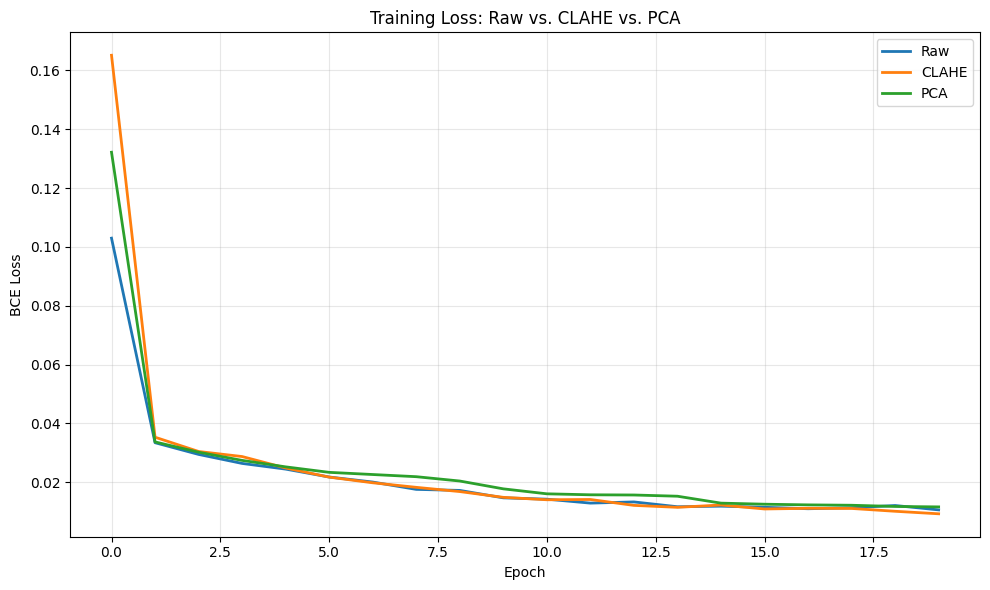

In [ ]:
# ============================================================
# Training Loop
# ============================================================
import os
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

NUM_EPOCHS = 20
LR = 1e-3

def train_model(model, train_loader, num_epochs=NUM_EPOCHS, lr=LR):
    """Train a segmentation model and return loss history."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()  # Binary segmentation

    loss_history = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        n_batches = 0

        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)

            optimizer.zero_grad()
            outputs = model(images)  # logits
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1

        epoch_loss = running_loss / n_batches
        loss_history.append(epoch_loss)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'  Epoch [{epoch+1}/{num_epochs}]  Loss: {epoch_loss:.4f}')

    return loss_history

# Create a folder for the trained models in your results directory
models_folder = os.path.join(resultsFolderPath, 'trained_models')
os.makedirs(models_folder, exist_ok=True)

# Define file paths
raw_model_path = os.path.join(models_folder, 'model_raw.pth')
clahe_model_path = os.path.join(models_folder, 'model_clahe.pth')
pca_model_path = os.path.join(models_folder, 'model_pca.pth')

# --- Train Model A: Raw data ---
print('\n' + '='*50)
print('Training Model A (RAW data)')
print('='*50)
model_raw = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1)
loss_raw = train_model(model_raw, train_loader_raw)
torch.save(model_raw.state_dict(), raw_model_path)
print(f"Model saved successfully to {raw_model_path}")

# --- Train Model B: CLAHE data ---
print('\n' + '='*50)
print('Training Model B (CLAHE data)')
print('='*50)
model_clahe = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1)
loss_clahe = train_model(model_clahe, train_loader_clahe)
torch.save(model_clahe.state_dict(), clahe_model_path)
print(f"Model saved successfully to {clahe_model_path}")

# --- Train Model C: PCA data ---
print('\n' + '='*50)
print('Training Model C (PCA data)')
print('='*50)
model_pca = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1)
loss_pca = train_model(model_pca, train_loader_pca)
torch.save(model_pca.state_dict(), pca_model_path)
print(f"Model saved successfully to {pca_model_path}")

# --- Plot training curves ---
plt.figure(figsize=(10, 6))
plt.plot(loss_raw, label='Raw', linewidth=2)
plt.plot(loss_clahe, label='CLAHE', linewidth=2)
plt.plot(loss_pca, label='PCA', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('BCE Loss')
plt.title('Training Loss: Raw vs. CLAHE vs. PCA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
# Ensure x-axis labels are integer epochs (e.g., 1, 2, 3... 20)
epochs = range(1, len(loss_raw) + 1)
plt.xticks(np.arange(1, len(epochs) + 1, step=1))
plt.show()

Using the trained models, run them on the remaining data. Three metrics are used to evaluate the model results. The Dice score calculates the size of the intersection of two sets divided by the average size of the two sets. Next, the IoU score calculates the area of overlap between the predicted mask and the ground truth mask divided by the total area combined by both masks. Finally, pixel accuracy calculates the ratio of correctly classified pixels (both target and background) to the total number of pixels in the image.

In our case, pixel accuracy is the least helpful as the background occupies most of the image. Dice is good, as it can handle this imbalance of background to target. Lastly, IoU is also useful, though it penalizes single instances of bad classification more strictly than Dice does.

In [12]:
# ============================================================
# Evaluation Metrics
# ============================================================

def dice_score(pred, target, threshold=0.5):
    """Compute Dice coefficient (2*intersection / union)."""
    pred_bin = (pred > threshold).float()
    intersection = (pred_bin * target).sum()
    return (2.0 * intersection / (pred_bin.sum() + target.sum() + 1e-8)).item()

def iou_score(pred, target, threshold=0.5):
    """Compute Intersection over Union (Jaccard index)."""
    pred_bin = (pred > threshold).float()
    intersection = (pred_bin * target).sum()
    union = pred_bin.sum() + target.sum() - intersection
    return (intersection / (union + 1e-8)).item()

def pixel_accuracy(pred, target, threshold=0.5):
    """Compute pixel-wise accuracy."""
    pred_bin = (pred > threshold).float()
    correct = (pred_bin == target).sum()
    total = target.numel()
    return (correct / total).item()

In [ ]:



def evaluate_model(model, test_loader, label='Model'):
    """Run model on test set, compute metrics per sample."""
    model.eval()
    model.to(device)

    all_dice, all_iou, all_acc = [], [], []

    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            probs = torch.sigmoid(logits)

            for i in range(probs.shape[0]):
                all_dice.append(dice_score(probs[i], masks[i]))
                all_iou.append(iou_score(probs[i], masks[i]))
                all_acc.append(pixel_accuracy(probs[i], masks[i]))

    results = {
        'Dice':     np.mean(all_dice),
        'IoU':      np.mean(all_iou),
        'Pixel Acc': np.mean(all_acc),
        'dice_all': all_dice,
        'iou_all':  all_iou,
    }
    print(f'\n{label} Results on {len(all_dice)} test samples:')
    print(f'  Dice Score:     {results["Dice"]:.4f}')
    print(f'  IoU:            {results["IoU"]:.4f}')
    print(f'  Pixel Accuracy: {results["Pixel Acc"]:.4f}')

    return results


# --- Evaluate all models ---
print('='*50)
results_raw = evaluate_model(model_raw, test_loader_raw, label='RAW')
print('='*50)
results_clahe = evaluate_model(model_clahe, test_loader_clahe, label='CLAHE')
print('='*50)
results_pca = evaluate_model(model_pca, test_loader_pca, label='PCA')


RAW Results on 203 test samples:
  Dice Score:     0.5210
  IoU:            0.4163
  Pixel Accuracy: 0.9894

CLAHE Results on 203 test samples:
  Dice Score:     0.6139
  IoU:            0.5043
  Pixel Accuracy: 0.9910

PCA Results on 203 test samples:
  Dice Score:     0.5843
  IoU:            0.4748
  Pixel Accuracy: 0.9902


Let's save all the test scores to Google Drive in case we need to run more analysis later.

In [ ]:
#save all individual test scores for each sample and model in csv for further analysis
import pandas as pd
import os

# Create a DataFrame with the per-sample scores
scores_df = pd.DataFrame({
    'Sample_Index': range(len(results_raw['dice_all'])),
    'Raw_Dice': results_raw['dice_all'],
    'Raw_IoU': results_raw['iou_all'],
    'CLAHE_Dice': results_clahe['dice_all'],
    'CLAHE_IoU': results_clahe['iou_all'],
    'PCA_Dice': results_pca['dice_all'],
    'PCA_IoU': results_pca['iou_all']
})

# Define the save path
csv_path = os.path.join(resultsFolderPath, 'per_sample_metrics.csv')

# Save to CSV
scores_df.to_csv(csv_path, index=False)
print(f"Successfully saved per-sample metrics to {csv_path}")

# Display the first few rows of the saved data
display(scores_df.head())

Successfully saved per-sample metrics to /content/drive/MyDrive/Duke/BME303/finalProject/results/per_sample_metrics.csv


,Sample_Index,Raw_Dice,Raw_IoU,CLAHE_Dice,CLAHE_IoU,PCA_Dice,PCA_IoU
0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,0.835165,0.716981,0.887015,0.796970,0.880829,0.787037
2,2,0.344784,0.208301,0.338405,0.203663,0.325463,0.194360
3,3,0.622951,0.452381,0.705761,0.545310,0.706447,0.546129
4,4,0.819977,0.694882,0.867760,0.766409,0.903627,0.824197


Let's compare the results. First, run a T-test to determine any statistically significant differences. You can load the results directly from CoLab local memory if you already ran all the cells, or just load it from the saved csv.

Loading metrics from CSV...


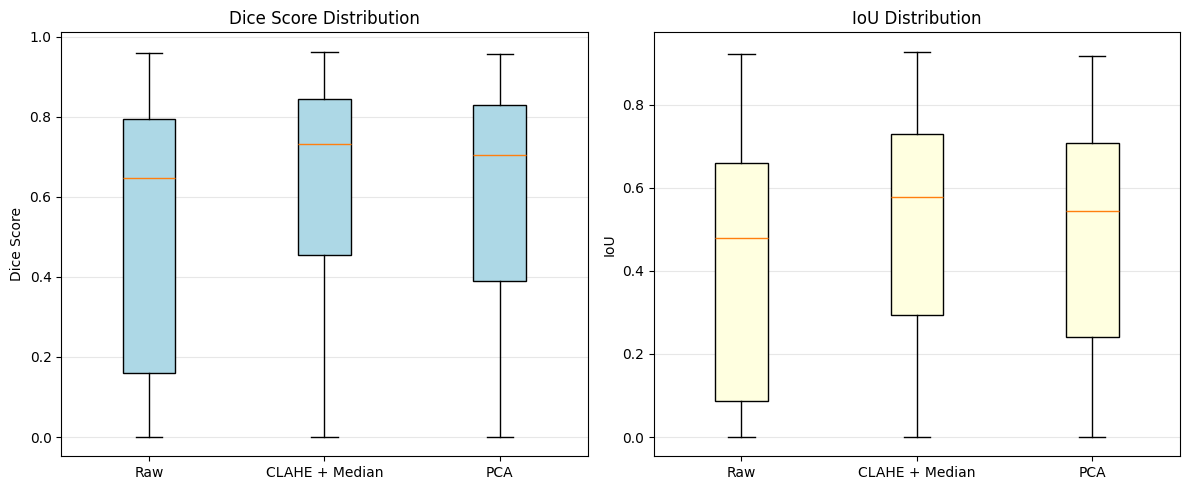

DICE SCORE COMPARISONS

Paired t-test on Dice scores (Raw vs CLAHE + Median):
  t-statistic: -4.4083
  p-value:     0.0000
  → Statistically significant difference (p < 0.05). CLAHE + Median is better.

Paired t-test on Dice scores (Raw vs PCA):
  t-statistic: -3.3279
  p-value:     0.0010
  → Statistically significant difference (p < 0.05). PCA is better.

Paired t-test on Dice scores (CLAHE + Median vs PCA):
  t-statistic: 1.5502
  p-value:     0.1227
  → No statistically significant difference (p >= 0.05).

IOU SCORE COMPARISONS

Paired t-test on IoU scores (Raw vs CLAHE + Median):
  t-statistic: -4.7689
  p-value:     0.0000
  → Statistically significant difference (p < 0.05). CLAHE + Median is better.

Paired t-test on IoU scores (Raw vs PCA):
  t-statistic: -3.5090
  p-value:     0.0006
  → Statistically significant difference (p < 0.05). PCA is better.

Paired t-test on IoU scores (CLAHE + Median vs PCA):
  t-statistic: 1.7123
  p-value:     0.0884
  → No statistically significa

In [ ]:
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# ============================================================
# Toggle for Loading from CSV
# ============================================================
LOAD_FROM_CSV = True  # Set to True to skip running earlier cells and load from CSV

if LOAD_FROM_CSV:
    print("Loading metrics from CSV...")
    csv_path = os.path.join(resultsFolderPath, 'per_sample_metrics.csv')
    df = pd.read_csv(csv_path)

    # Reconstruct the results dictionaries by calculating averages from the CSV
    # Note: Pixel Acc was not saved in the CSV, so we use the overall average from the last run.
    results_raw = {
        'dice_all': df['Raw_Dice'].values,
        'iou_all': df['Raw_IoU'].values,
        'Dice': df['Raw_Dice'].mean(),
        'IoU': df['Raw_IoU'].mean(),
        'Pixel Acc': 0.9894
    }

    results_clahe = {
        'dice_all': df['CLAHE_Dice'].values,
        'iou_all': df['CLAHE_IoU'].values,
        'Dice': df['CLAHE_Dice'].mean(),
        'IoU': df['CLAHE_IoU'].mean(),
        'Pixel Acc': 0.9910
    }

    results_pca = {
        'dice_all': df['PCA_Dice'].values,
        'iou_all': df['PCA_IoU'].values,
        'Dice': df['PCA_Dice'].mean(),
        'IoU': df['PCA_IoU'].mean(),
        'Pixel Acc': 0.9902
    }
else:
    print("Using metrics from memory...")

# ============================================================
# Box Plot — Per-Sample Distribution
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Dice box plot
bp1 = axes[0].boxplot([results_raw['dice_all'], results_clahe['dice_all'], results_pca['dice_all']],
                       tick_labels=['Raw', 'CLAHE + Median', 'PCA'], patch_artist=True,
                       boxprops=dict(facecolor='lightblue'))
axes[0].set_title('Dice Score Distribution')
axes[0].set_ylabel('Dice Score')
axes[0].grid(axis='y', alpha=0.3)

# IoU box plot
bp2 = axes[1].boxplot([results_raw['iou_all'], results_clahe['iou_all'], results_pca['iou_all']],
                       tick_labels=['Raw', 'CLAHE + Median', 'PCA'], patch_artist=True,
                       boxprops=dict(facecolor='lightyellow'))
axes[1].set_title('IoU Distribution')
axes[1].set_ylabel('IoU')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# Paired t-test: Is the difference statistically significant?
# ============================================================
def perform_ttest(metric, model1_name, scores1, model2_name, scores2):
    t_stat, p_val = stats.ttest_rel(scores1, scores2)
    print(f'\nPaired t-test on {metric} scores ({model1_name} vs {model2_name}):')
    print(f'  t-statistic: {t_stat:.4f}')
    print(f'  p-value:     {p_val:.4f}')
    if p_val < 0.05:
        better = model2_name if np.mean(scores2) > np.mean(scores1) else model1_name
        print(f'  → Statistically significant difference (p < 0.05). {better} is better.')
    else:
        print(f'  → No statistically significant difference (p >= 0.05).')

print("="*50)
print("DICE SCORE COMPARISONS")
print("="*50)
perform_ttest('Dice', 'Raw', results_raw['dice_all'], 'CLAHE + Median', results_clahe['dice_all'])
perform_ttest('Dice', 'Raw', results_raw['dice_all'], 'PCA', results_pca['dice_all'])
perform_ttest('Dice', 'CLAHE + Median', results_clahe['dice_all'], 'PCA', results_pca['dice_all'])

print("\n" + "="*50)
print("IOU SCORE COMPARISONS")
print("="*50)
perform_ttest('IoU', 'Raw', results_raw['iou_all'], 'CLAHE + Median', results_clahe['iou_all'])
perform_ttest('IoU', 'Raw', results_raw['iou_all'], 'PCA', results_pca['iou_all'])
perform_ttest('IoU', 'CLAHE + Median', results_clahe['iou_all'], 'PCA', results_pca['iou_all'])

Let's make a bar chart to visualize the differences.

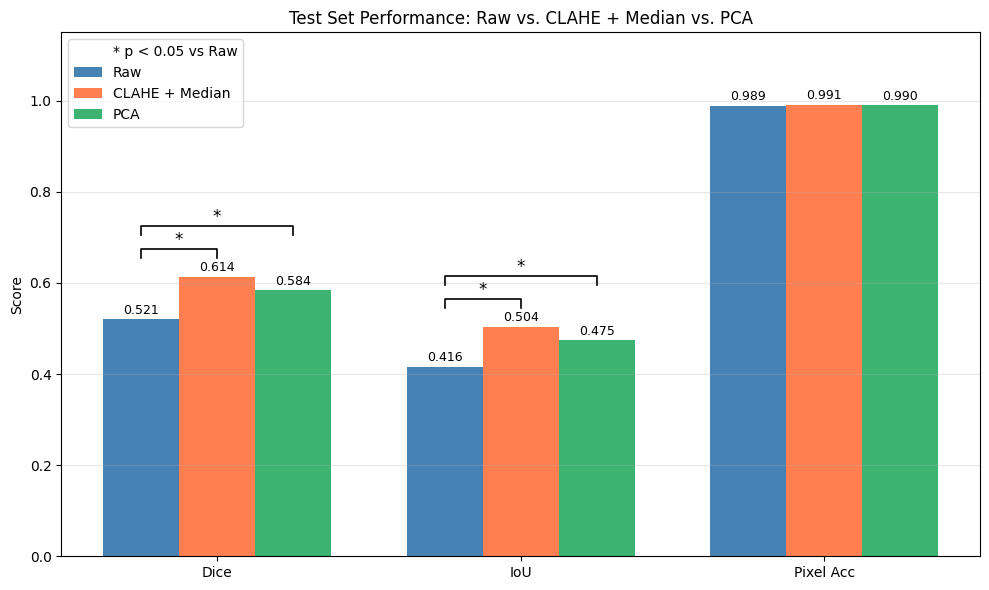

In [ ]:
# ============================================================
# Bar Chart Comparison
# ============================================================

metrics = ['Dice', 'IoU', 'Pixel Acc']
raw_vals = [results_raw[m] for m in metrics]
clahe_vals = [results_clahe[m] for m in metrics]
pca_vals = [results_pca[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, raw_vals, width, label='Raw', color='steelblue')
bars2 = ax.bar(x, clahe_vals, width, label='CLAHE + Median', color='coral')
bars3 = ax.bar(x + width, pca_vals, width, label='PCA', color='mediumseagreen')

ax.set_ylabel('Score')
ax.set_title('Test Set Performance: Raw vs. CLAHE + Median vs. PCA')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)  # Increased upper limit to make room for annotations

# Add significance to legend
ax.plot([], [], ' ', label='* p < 0.05 vs Raw')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar_group in [bars1, bars2, bars3]:
    for bar in bar_group:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

# Function to add statistical annotation
def add_stat_annotation(ax, x1, x2, y, h, text='*'):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c='k')
    ax.text((x1+x2)*.5, y+h, text, ha='center', va='bottom', color='k', fontsize=12)

# Annotate significant differences for Dice (x = 0)
max_dice_clahe = max(raw_vals[0], clahe_vals[0])
add_stat_annotation(ax, x[0] - width, x[0], max_dice_clahe + 0.04, 0.02)

max_dice_pca = max(raw_vals[0], pca_vals[0])
add_stat_annotation(ax, x[0] - width, x[0] + width, max_dice_pca + 0.12, 0.02)

# Annotate significant differences for IoU (x = 1)
max_iou_clahe = max(raw_vals[1], clahe_vals[1])
add_stat_annotation(ax, x[1] - width, x[1], max_iou_clahe + 0.04, 0.02)

max_iou_pca = max(raw_vals[1], pca_vals[1])
add_stat_annotation(ax, x[1] - width, x[1] + width, max_iou_pca + 0.12, 0.02)

plt.tight_layout()
plt.show()

Lastly, let's make a figure that visually compares the different pre-processing methods, and the corresponding predicted masks versus the known ground truth annotations.

test_pairs not found in memory. Recreating the split on the fly...
Loading saved models from Google Drive...


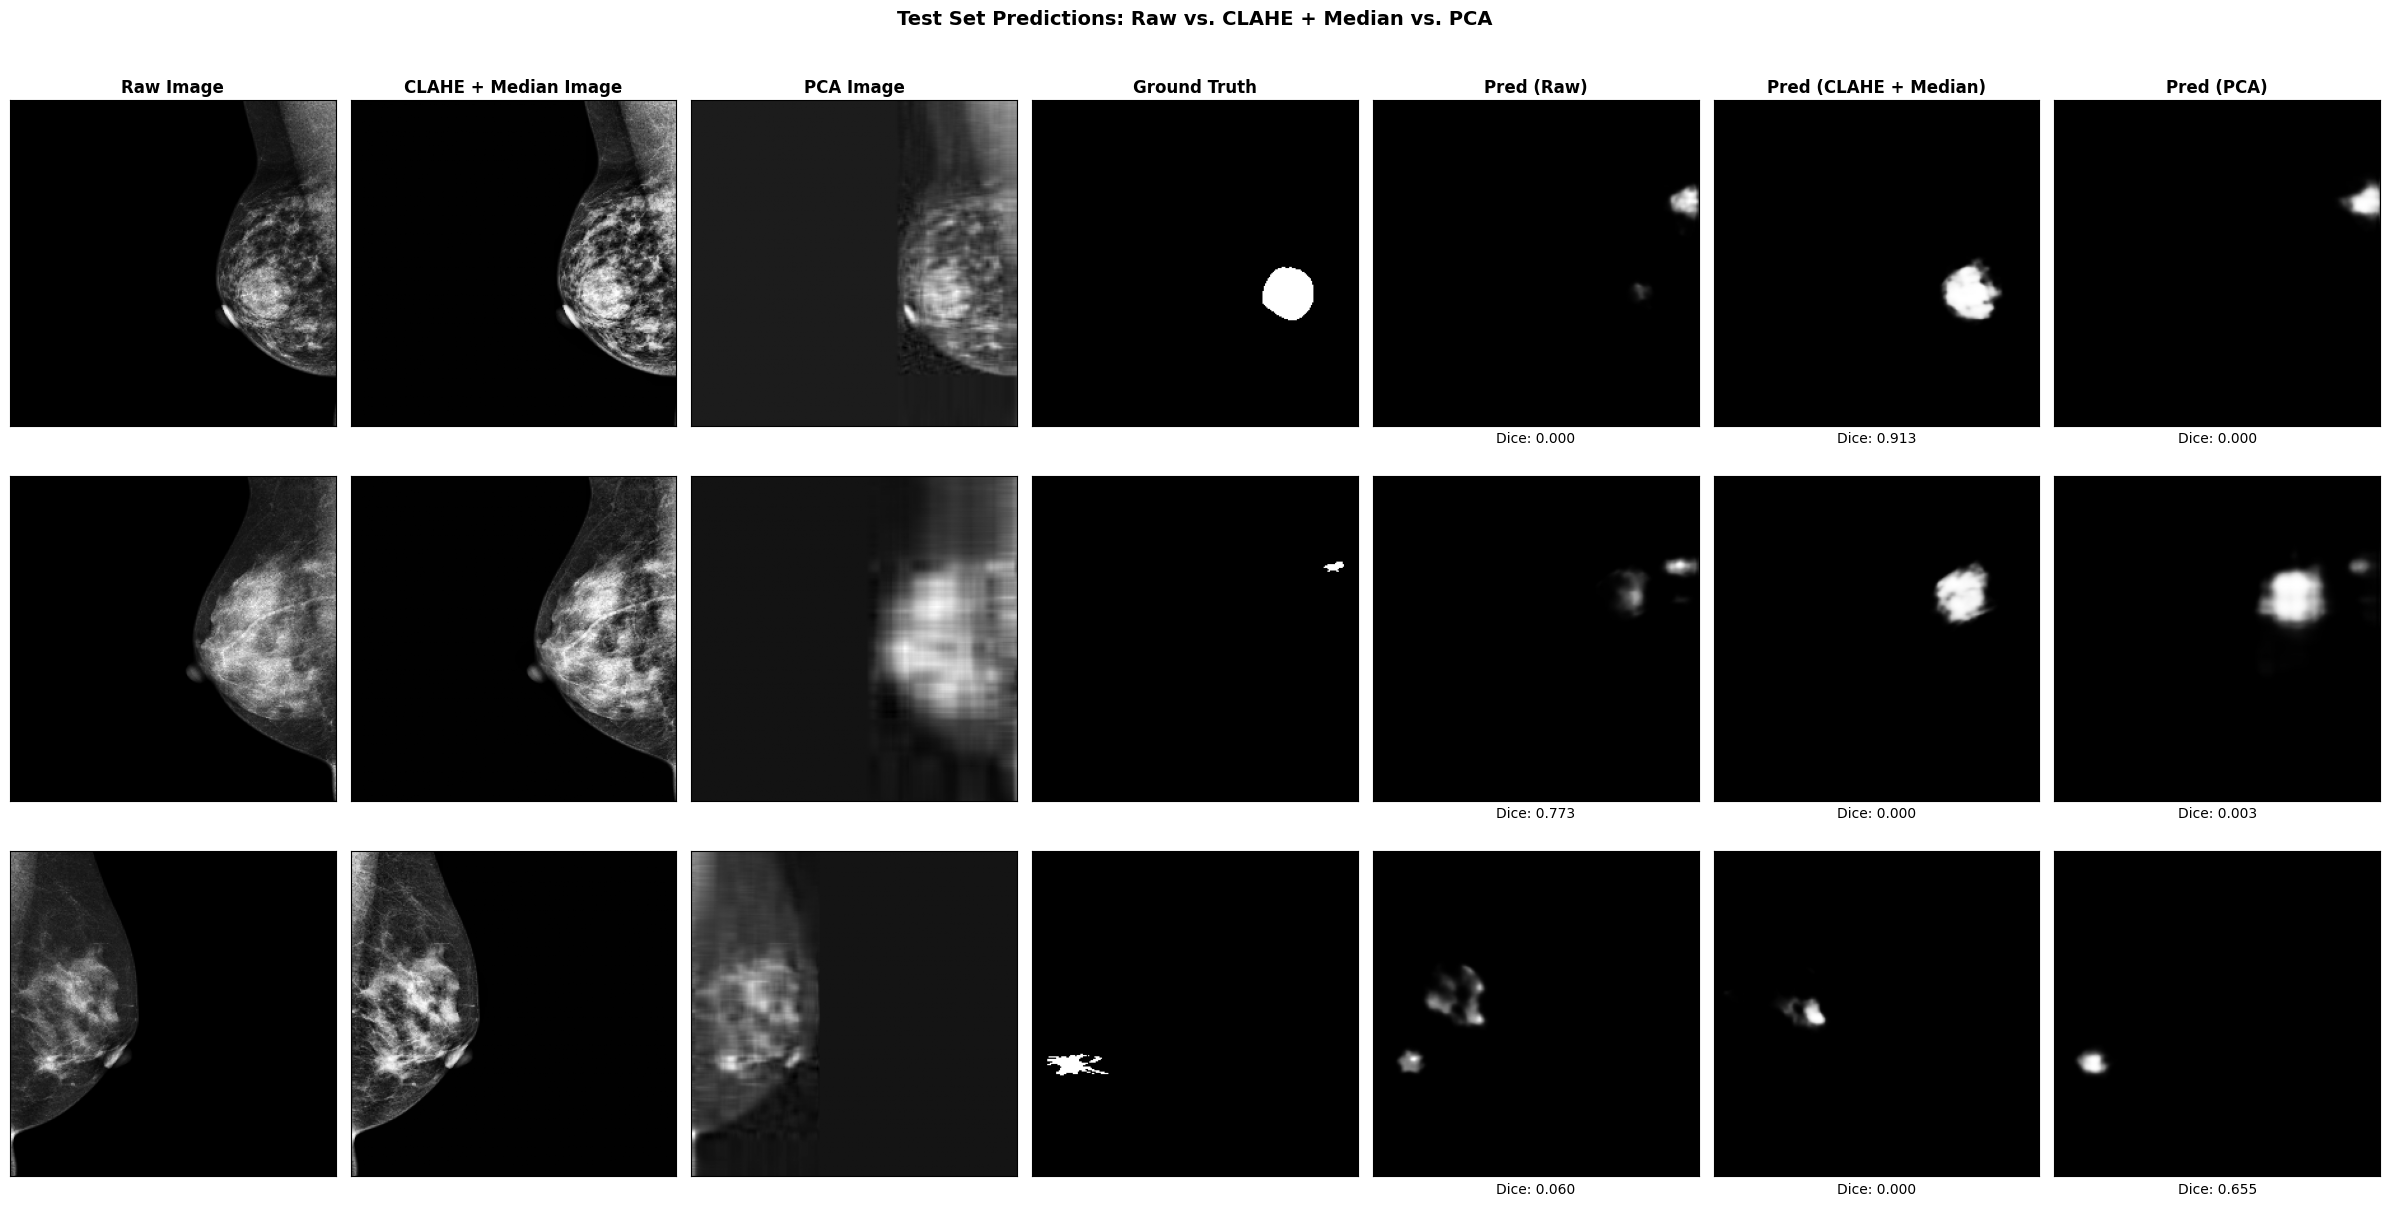

In [26]:
import os
import cv2
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
import glob
from sklearn.model_selection import train_test_split

# ============================================================
# Evaluation Metrics Helpers
# ============================================================
def dice_score(pred, target, threshold=0.5):
    """Compute Dice coefficient (2*intersection / union)."""
    pred_bin = (pred > threshold).float()
    intersection = (pred_bin * target).sum()
    return (2.0 * intersection / (pred_bin.sum() + target.sum() + 1e-8)).item()

# ============================================================
# Qualitative Visual Comparison
# ============================================================

test_image_index = [17, 70, 117]
NUM_EXAMPLES = len(test_image_index)

if 'test_pairs' in globals():
    image_names = [os.path.basename(test_pairs[idx][0]).replace('.png', '') for idx in test_image_index]
else:
    print('test_pairs not found in memory. Recreating the split on the fly...')
    all_images = sorted(glob.glob('/content/dataset/**/*.png', recursive=True))
    all_annotations = sorted(glob.glob('/content/dataset/**/*.json', recursive=True))
    all_pairs = list(zip(all_images, all_annotations))
    _, recreated_test_pairs = train_test_split(all_pairs, test_size=0.2, random_state=42)
    image_names = [os.path.basename(recreated_test_pairs[idx][0]).replace('.png', '') for idx in test_image_index]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Check toggle to load models from Drive
if LOAD_FROM_CSV:
    print("Loading saved models from Google Drive...")
    models_folder = os.path.join(resultsFolderPath, 'trained_models')

    model_raw = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1).to(device)
    model_raw.load_state_dict(torch.load(os.path.join(models_folder, 'model_raw.pth'), map_location=device))

    model_clahe = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1).to(device)
    model_clahe.load_state_dict(torch.load(os.path.join(models_folder, 'model_clahe.pth'), map_location=device))

    model_pca = smp.Unet(encoder_name="efficientnet-b0", in_channels=1, classes=1).to(device)
    model_pca.load_state_dict(torch.load(os.path.join(models_folder, 'model_pca.pth'), map_location=device))

model_raw.eval()
model_clahe.eval()
model_pca.eval()

# Folder definitions for preprocessed images in Drive
drive_clahe_folder = os.path.join(resultsFolderPath, 'preProcessed_CLAHE')
drive_pca_folder = os.path.join(resultsFolderPath, 'preProcessed_PCA')
IMG_SIZE = 256

raw_imgs_list, clahe_imgs_list, pca_imgs_list, masks_list = [], [], [], []

def prepare_tensor(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not load {img_path}")
    img = img.astype(np.float32)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / (img.max() + 1e-8)
    return torch.tensor(img, dtype=torch.float32).unsqueeze(0)

for name in image_names:
    # Load Raw Image from local memory using glob
    raw_search = glob.glob(f'/content/dataset/images/{name}*.png')
    if not raw_search:
        raise FileNotFoundError(f"Image for {name} not found.")
    raw_path = raw_search[0]
    raw_imgs_list.append(prepare_tensor(raw_path))

    # Load Preprocessed Images from Drive
    clahe_path = os.path.join(drive_clahe_folder, f'{name}_clahe.png')
    clahe_imgs_list.append(prepare_tensor(clahe_path))

    pca_path = os.path.join(drive_pca_folder, f'{name}_pca.png')
    pca_imgs_list.append(prepare_tensor(pca_path))

    # Load Annotation using glob
    ann_search = glob.glob(f'/content/dataset/annotations/{name}*.json')
    if not ann_search:
        raise FileNotFoundError(f"Annotation for {name} not found.")
    ann_path = ann_search[0]

    with open(ann_path, 'r') as f:
        ann = json.load(f)

    # Generate mask
    original_img_shape = cv2.imread(raw_path, cv2.IMREAD_GRAYSCALE).shape
    mask = annotation_to_mask(ann, original_img_shape[0], original_img_shape[1])
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    masks_list.append(torch.tensor(mask, dtype=torch.float32).unsqueeze(0))

# Stack lists into batches: Shape (B, 1, H, W)
raw_imgs = torch.stack(raw_imgs_list)
clahe_imgs = torch.stack(clahe_imgs_list)
pca_imgs = torch.stack(pca_imgs_list)
raw_masks = torch.stack(masks_list)
clahe_masks = raw_masks  # Same ground truth mask
pca_masks = raw_masks

with torch.no_grad():
    raw_preds = torch.sigmoid(model_raw(raw_imgs.to(device))).cpu()
    clahe_preds = torch.sigmoid(model_clahe(clahe_imgs.to(device))).cpu()
    pca_preds = torch.sigmoid(model_pca(pca_imgs.to(device))).cpu()

n_show = len(image_names)
fig, axes = plt.subplots(n_show, 7, figsize=(24, 4 * n_show))
if n_show == 1:
    axes = axes[np.newaxis, :]

col_titles = ['Raw Image', 'CLAHE + Median Image', 'PCA Image', 'Ground Truth', 'Pred (Raw)', 'Pred (CLAHE + Median)', 'Pred (PCA)']
for j, t in enumerate(col_titles):
    axes[0, j].set_title(t, fontsize=12, fontweight='bold')

for i, name in enumerate(image_names):
    axes[i, 0].imshow(raw_imgs[i, 0], cmap='gray')
    axes[i, 1].imshow(clahe_imgs[i, 0], cmap='gray')
    axes[i, 2].imshow(pca_imgs[i, 0], cmap='gray')
    axes[i, 3].imshow(raw_masks[i, 0], cmap='gray')
    axes[i, 4].imshow(raw_preds[i, 0], cmap='gray')
    axes[i, 5].imshow(clahe_preds[i, 0], cmap='gray')
    axes[i, 6].imshow(pca_preds[i, 0], cmap='gray')

    # Fetch dice scores
    if LOAD_FROM_CSV and 'df' in globals():
        csv_idx = test_image_index[i]
        d_raw = df.loc[csv_idx, 'Raw_Dice']
        d_clahe = df.loc[csv_idx, 'CLAHE_Dice']
        d_pca = df.loc[csv_idx, 'PCA_Dice']
    else:
        d_raw = dice_score(raw_preds[i], raw_masks[i])
        d_clahe = dice_score(clahe_preds[i], clahe_masks[i])
        d_pca = dice_score(pca_preds[i], pca_masks[i])

    axes[i, 4].set_xlabel(f'Dice: {d_raw:.3f}', fontsize=10)
    axes[i, 5].set_xlabel(f'Dice: {d_clahe:.3f}', fontsize=10)
    axes[i, 6].set_xlabel(f'Dice: {d_pca:.3f}', fontsize=10)

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Test Set Predictions: Raw vs. CLAHE + Median vs. PCA', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


Make sure to save all the plots we made to Google Drive. You are all done!

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Ensure the results folder exists
os.makedirs(resultsFolderPath, exist_ok=True)

# 1. Save Qualitative Visual Comparison
qualitative_fig_path = os.path.join(resultsFolderPath, 'qualitative_comparison.png')
fig.savefig(qualitative_fig_path, bbox_inches='tight')
print(f"Saved qualitative comparison to {qualitative_fig_path}")

# 2. Save Bar Chart Comparison
bar_chart_fig_path = os.path.join(resultsFolderPath, 'bar_chart_comparison.png')
x = np.arange(len(metrics))
width = 0.25
fig_bar, ax_bar = plt.subplots(figsize=(10, 6))
bars1 = ax_bar.bar(x - width, raw_vals, width, label='Raw', color='steelblue')
bars2 = ax_bar.bar(x, clahe_vals, width, label='CLAHE + Median', color='coral')
bars3 = ax_bar.bar(x + width, pca_vals, width, label='PCA', color='mediumseagreen')

ax_bar.set_ylabel('Score')
ax_bar.set_title('Test Set Performance: Raw vs. CLAHE + Median vs. PCA')
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(metrics)
ax_bar.set_ylim(0, 1)
ax_bar.legend()
ax_bar.grid(axis='y', alpha=0.3)
for bar_group in [bars1, bars2, bars3]:
    for bar in bar_group:
        ax_bar.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
fig_bar.tight_layout()
fig_bar.savefig(bar_chart_fig_path, bbox_inches='tight')
plt.close(fig_bar)
print(f"Saved bar chart comparison to {bar_chart_fig_path}")


# 3. Save Metrics and T-Test Results to a text file
metrics_txt_path = os.path.join(resultsFolderPath, 'metrics_summary.txt')
with open(metrics_txt_path, 'w') as f:
    f.write('='*75 + '\n')
    f.write(f'{"Metric":<15} {"Raw":>10} {"CLAHE + Median":>20} {"PCA":>15}\n')
    f.write('='*75 + '\n')
    for m in metrics:
        f.write(f'{m:<15} {results_raw[m]:>10.4f} {results_clahe[m]:>20.4f} {results_pca[m]:>15.4f}\n')
    f.write('='*75 + '\n\n')

    f.write('='*75 + '\n')
    f.write('Paired t-test on Dice scores (Raw vs CLAHE + Median):\n')
    t_stat, p_val = stats.ttest_rel(results_raw['dice_all'], results_clahe['dice_all'])
    f.write(f'  t-statistic: {t_stat:.4f}\n')
    f.write(f'  p-value:     {p_val:.4f}\n')
    if p_val < 0.05:
        better = 'CLAHE + Median' if np.mean(results_clahe['dice_all']) > np.mean(results_raw['dice_all']) else 'Raw'
        f.write(f'  → Statistically significant difference (p < 0.05). {better} is better.\n')
    else:
        f.write(f'  → No statistically significant difference (p >= 0.05).\n')

    f.write('\nPaired t-test on Dice scores (Raw vs PCA):\n')
    t_stat, p_val = stats.ttest_rel(results_raw['dice_all'], results_pca['dice_all'])
    f.write(f'  t-statistic: {t_stat:.4f}\n')
    f.write(f'  p-value:     {p_val:.4f}\n')
    if p_val < 0.05:
        better = 'PCA' if np.mean(results_pca['dice_all']) > np.mean(results_raw['dice_all']) else 'Raw'
        f.write(f'  → Statistically significant difference (p < 0.05). {better} is better.\n')
    else:
        f.write(f'  → No statistically significant difference (p >= 0.05).\n')

print(f"Saved metrics summary to {metrics_txt_path}")

Saved qualitative comparison to /content/drive/MyDrive/Duke/BME303/finalProject/results/qualitative_comparison.png
Saved bar chart comparison to /content/drive/MyDrive/Duke/BME303/finalProject/results/bar_chart_comparison.png
Saved metrics summary to /content/drive/MyDrive/Duke/BME303/finalProject/results/metrics_summary.txt
